# 01. Покрытие METAR на момент C40

**Задача:** проверить, есть ли предшествующая погода для обычных посадок и GoA.
Пилот охватывает EGCC, EGLL и LFPG за январь и июль 2019 года по времени C40 UTC.
Полные месяцы включают все дни; аэропорты не ранжировались по частоте GoA.

Здесь выполнены код сопоставления, таблицы покрытия и графики. Исходная база
не изменяется. Это техническая проверка шести групп, а не оценка всей базы
или доказательство доступности погоды в реальном прогнозе.

[Следующий ноутбук: погодные признаки](02_metar_decoding.ipynb) ·
[Протокол](../reports/02_pilot_protocol.md) ·
[IEM — описание архива](https://mesonet.agron.iastate.edu/info/datasets/metar.html)

## 1. Проверка происхождения

SHA256 фиксирует конкретную версию данных. Проверяем аналитический вход и
все шесть сохраненных ответов IEM; повторной загрузки при исполнении нет.

In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from html import escape
from cycler import cycler

BASE = Path.cwd().resolve()
while not (BASE / 'reports/03_pilot_manifest.json').exists():
    if BASE == BASE.parent:
        raise FileNotFoundError('Не найдена папка europe/weather с выполненным пилотом')
    BASE = BASE.parent
PROJECT = BASE.parents[1]
R, F, DATA = BASE / 'reports', BASE / 'figures', BASE / 'data'
F.mkdir(exist_ok=True)
sys.path.insert(0, str(BASE / 'scripts'))
manifest = json.loads((R / '03_pilot_manifest.json').read_text(encoding='utf8'))
def sha(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()
assert sha(PROJECT / 'europe/data/analytical/06_05_cases_excluded.parquet') == manifest['input_sha256']
for source in manifest['downloads']:
    path = DATA / 'raw' / f"{source['airport']}_{source['month']}.csv"
    assert sha(path) == source['sha256']

GREEN, CORAL, LIGHT_GREEN, LIGHT_CORAL = '#00897B', '#D65A4A', '#80CBC4', '#E69A90'
plt.rcParams.update({'figure.dpi':120, 'font.size':11, 'axes.spines.top':False,
    'axes.spines.right':False, 'axes.grid':True, 'grid.alpha':.16,
    'axes.prop_cycle':cycler(color=[CORAL, GREEN, LIGHT_CORAL, LIGHT_GREEN])})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_colwidth', 100)
def save(name):
    plt.tight_layout()
    for ext in ['png', 'svg']:
        plt.savefig(F / f'{name}.{ext}', bbox_inches='tight')
    plt.show()
def readable_table(frame):
    html = frame.to_html(index=False, escape=True)
    display(HTML('<div style="max-width:100%;overflow:auto">' + html + '</div>'))


In [2]:
audit = json.loads((R / '01_input_audit.json').read_text(encoding='utf8'))
matches = pd.read_parquet(DATA / '03_pilot_matches.parquet')
assert len(matches) == manifest['rows'] and matches.source_row.is_unique
assert int(matches.GoA.sum()) == manifest['go_arounds']
summary = pd.DataFrame([
    {'Показатель':'Исходные записи', 'Значение':audit['rows']},
    {'Показатель':'Исходные GoA', 'Значение':audit['go_arounds']},
    {'Показатель':'Записи пилота', 'Значение':len(matches)},
    {'Показатель':'GoA пилота', 'Значение':int(matches.GoA.sum())},
    {'Показатель':'Архивные METAR, включая предшествующие сутки',
     'Значение':sum(x['raw_reports'] for x in manifest['downloads'])},
])
display(summary)
source_table = pd.DataFrame(manifest['downloads'])[
    ['airport','month','raw_reports','ambiguous_times','correction_reports','downloaded_utc']]
display(source_table)


,Показатель,Значение
0,Исходные записи,6331485
1,Исходные GoA,18349
2,Записи пилота,76741
3,GoA пилота,307
4,"Архивные METAR, включая предшествующие сутки",9223


,airport,month,raw_reports,ambiguous_times,correction_reports,downloaded_utc
0,EGCC,2019-01,1535,0,6,2026-10-10T19:33:37.856274+00:00
1,EGCC,2019-07,1536,0,2,2026-10-10T19:34:11.942231+00:00
2,EGLL,2019-01,1535,0,6,2026-10-10T19:34:14.197476+00:00
3,EGLL,2019-07,1536,0,2,2026-10-10T19:34:16.338513+00:00
4,LFPG,2019-01,1544,0,0,2026-10-10T19:34:18.513577+00:00
5,LFPG,2019-07,1537,0,0,2026-10-10T19:34:20.601915+00:00


## 2. Критерии выбора аэропортов и периодов наблюдения

EGCC включен как исходная станция технического пилота. EGLL и LFPG — два других аэропорта с наибольшим
по объему записей с C40 не позже первой попытки. В этой аналитической выборке
время C40 заполнено и удовлетворяет условию для всех записей.
Январь и июль 2019 года выбраны как два календарных месяца разных сезонов.
Такой выбор не обеспечивает репрезентативность погодных условий за год и не позволяет оценить сезонный эффект.

Выбор станций основан на объеме исходных записей и не использует частоту GoA.
Пилот предназначен для проверки сопоставления и декодирования METAR; его результаты не обобщаются на все аэропорты.

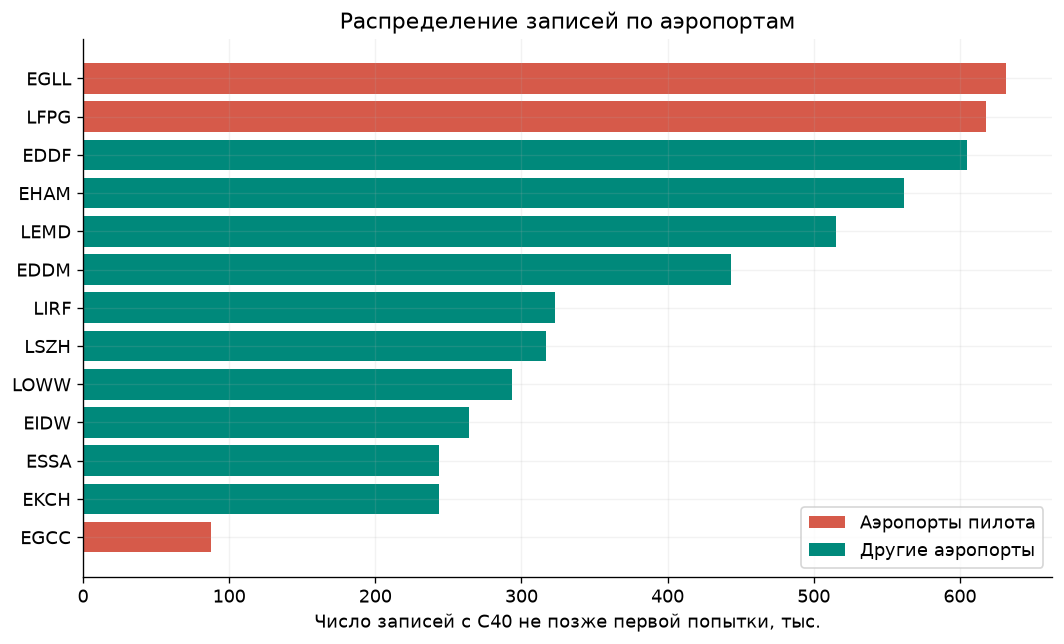

,airport,rows,go_arounds,c40_early,c40_early_percent
0,EGLL,631718,2400,631718,100.0
1,LFPG,617562,2346,617562,100.0
18,EGCC,87435,306,87435,100.0


GoA              Обычная посадка  GoA
airport month                        
EGCC    2019-01             3461   33
        2019-07             6273   21
EGLL    2019-01            14896   63
        2019-07            19722   56
LFPG    2019-01            13701   70
        2019-07            18381   64

In [3]:
airports = pd.read_csv(R / '01_airport_coverage.csv').sort_values('c40_early', ascending=False)
top = pd.concat([airports.head(12),airports[airports.airport.isin(audit['selected_airports'])]])
top = top.drop_duplicates('airport').sort_values('c40_early')
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = [CORAL if a in audit['selected_airports'] else GREEN for a in top.airport]
ax.barh(top.airport, top.c40_early / 1000, color=colors)
ax.set_xlabel('Число записей с C40 не позже первой попытки, тыс.')
ax.set_title('Распределение записей по аэропортам')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=CORAL, label='Аэропорты пилота'),
                   Patch(facecolor=GREEN, label='Другие аэропорты')],
          loc='lower right', frameon=True)
save('01_airport_selection')
display(airports[airports.airport.isin(audit['selected_airports'])][
    ['airport','rows','go_arounds','c40_early','c40_early_percent']])
group = matches.groupby(['airport','month','GoA']).size().unstack('GoA', fill_value=0)
display(group.rename(columns={False:'Обычная посадка',True:'GoA'}))


## 3. Сопоставление METAR с записями на момент C40

Для каждого аэропорта выбираем последнее наблюдение **строго раньше C40**.
Основной предел — 60 минут; 30 и 90 минут — диагностические сценарии.
При различных текстах одного времени выставляем неоднозначность, не
заменяем ее более старой погодой. Одинаковые строки сворачиваем только в
рабочей таблице сопоставления; исходный ответ остается неизменным.

`source_row` сохраняет физический номер строки входного Parquet и кратность
наблюдений. Уникальность `flight_id` не предполагается.

In [4]:
recomputed = []
for source in manifest['downloads']:
    airport, month = source['airport'], source['month']
    raw = pd.read_csv(DATA / 'raw' / f'{airport}_{month}.csv', dtype=str, keep_default_na=False)
    raw['metar_utc'] = pd.to_datetime(raw.valid, utc=True).astype('datetime64[ns, UTC]')
    assert raw.station.eq(airport).all()
    raw = raw.drop_duplicates(['metar_utc','metar']).copy()
    raw['ambiguous'] = raw.duplicated('metar_utc', keep=False)
    raw = raw.drop_duplicates('metar_utc').sort_values('metar_utc')
    part = matches.loc[matches.airport.eq(airport) & matches.month.eq(month),
        ['source_row','airport','C40_CROSS_TIME','GoA']].sort_values('C40_CROSS_TIME')
    joined = pd.merge_asof(part, raw[['metar_utc','metar','ambiguous']],
        left_on='C40_CROSS_TIME', right_on='metar_utc', direction='backward',
        allow_exact_matches=False, tolerance=pd.Timedelta(minutes=90))
    joined['age_minutes'] = (joined.C40_CROSS_TIME-joined.metar_utc).dt.total_seconds()/60
    joined.loc[joined.ambiguous.eq(True),'metar'] = None
    recomputed.append(joined)
check = pd.concat(recomputed).sort_values('source_row').reset_index(drop=True)
expected = matches.sort_values('source_row').reset_index(drop=True)
fields = ['source_row','airport','C40_CROSS_TIME','GoA','metar_utc','metar','age_minutes']
pd.testing.assert_frame_equal(check[fields], expected[fields], check_dtype=False)
valid = check.metar_utc.notna()
assert check.loc[valid,'age_minutes'].gt(0).all()
assert check.loc[valid,'age_minutes'].le(90).all()
display(Markdown(f'Повторное сопоставление совпало для **{len(check):,} записей**. '
                 'Будущие наблюдения и равные C40 времена не использованы.'))


Повторное сопоставление совпало для **76,741 записей**. Будущие наблюдения и равные C40 времена не использованы.

## 4. Покрытие METAR для обычных посадок и GoA

Покрытие означает наличие однозначного архивного сообщения в заданном
временном окне. Оно не означает заполненность каждого погодного поля.
В каждой строке матрицы собственный знаменатель; числа GoA невелики.

,airport,month,Метка,rows,covered,coverage_percent
1,EGCC,2019-01,Обычная посадка,3461,3461,100.0
4,EGCC,2019-01,GoA,33,33,100.0
7,EGCC,2019-07,Обычная посадка,6273,6273,100.0
10,EGCC,2019-07,GoA,21,21,100.0
13,EGLL,2019-01,Обычная посадка,14896,14896,100.0
16,EGLL,2019-01,GoA,63,63,100.0
19,EGLL,2019-07,Обычная посадка,19722,19722,100.0
22,EGLL,2019-07,GoA,56,56,100.0
25,LFPG,2019-01,Обычная посадка,13701,13701,100.0
28,LFPG,2019-01,GoA,70,70,100.0


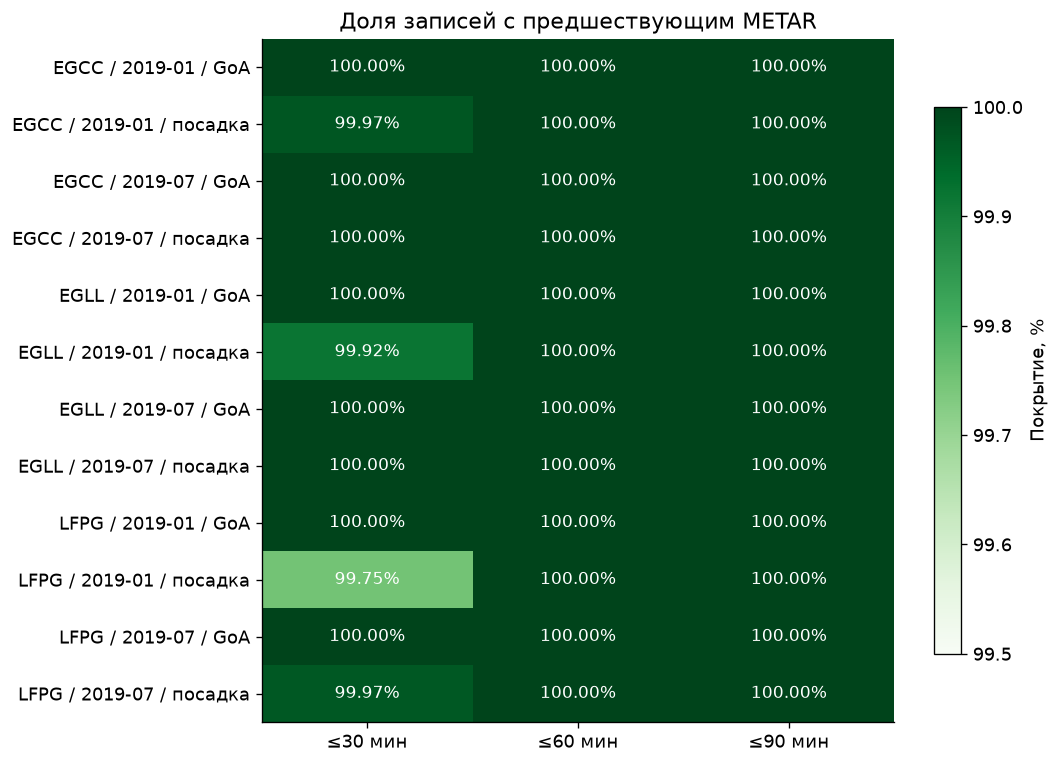

In [5]:
coverage_rows = []
for (airport, month, label), part in matches.groupby(['airport','month','GoA']):
    for age in [30,60,90]:
        covered = part.metar_utc.notna() & part.age_minutes.le(age) & ~part.ambiguous.eq(True)
        coverage_rows.append(dict(airport=airport,month=month,GoA=bool(label),
            max_age_minutes=age, rows=len(part), covered=int(covered.sum()),
            coverage_percent=100*covered.mean(), not_covered=int((~covered).sum())))
coverage = pd.DataFrame(coverage_rows)
persisted = pd.read_csv(R / '03_coverage.csv')
assert coverage.covered.tolist() == persisted.covered.tolist()
table = coverage.query('max_age_minutes == 60').copy()
table['Метка'] = table.GoA.map({False:'Обычная посадка',True:'GoA'})
display(table[['airport','month','Метка','rows','covered','coverage_percent']])
coverage['Группа'] = (coverage.airport + ' / ' + coverage.month + ' / ' +
    coverage.GoA.map({False:'посадка',True:'GoA'}))
matrix = coverage.pivot(index='Группа', columns='max_age_minutes', values='coverage_percent')
fig, ax = plt.subplots(figsize=(9,6.5))
im = ax.imshow(matrix, cmap='Greens', vmin=99.5, vmax=100, aspect='auto')
ax.set_yticks(range(len(matrix)), matrix.index)
ax.set_xticks(range(3), ['≤30 мин','≤60 мин','≤90 мин'])
ax.grid(False)
for i in range(len(matrix)):
    for j in range(3):
        ax.text(j,i,f'{matrix.iloc[i,j]:.2f}%',ha='center',va='center',color='white',fontsize=10)
ax.set_title('Доля записей с предшествующим METAR')
fig.colorbar(im, ax=ax, label='Покрытие, %', shrink=.8)
save('02_weather_coverage')


## 5. Давность наблюдений и чувствительность к порогу

Почти полное покрытие удобнее оценивать по числу непокрытых записей,
а не только по процентам. Порог 30 минут оставляет 53 обычные посадки без
подходящего сообщения; при 60 минутах покрыты все записи пилота.

rows  median    p95  maximum
airport month                                 
EGCC    2019-01   3494   14.77  28.50    58.53
        2019-07   6294   15.07  28.42    29.98
EGLL    2019-01  14959   15.10  28.45    56.37
        2019-07  19778   15.10  28.50    30.00
LFPG    2019-01  13771   14.95  28.47    56.13
        2019-07  18445   14.97  28.48    54.50

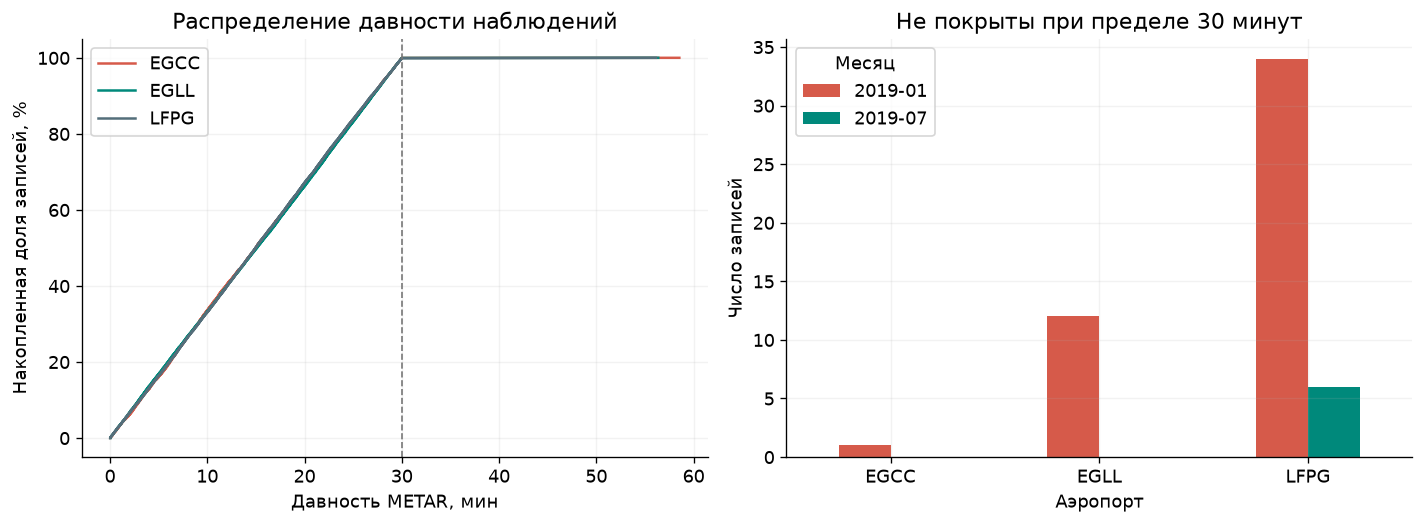

In [6]:
age_table = matches.groupby(['airport','month']).age_minutes.agg(
    rows='size', median='median', p95=lambda x:x.quantile(.95), maximum='max')
display(age_table.round(2))
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
for airport, color in zip(['EGCC','EGLL','LFPG'],[CORAL,GREEN,'#546E7A']):
    x = np.sort(matches.loc[matches.airport.eq(airport),'age_minutes'].dropna().to_numpy())
    axes[0].plot(x,np.arange(1,len(x)+1)/len(x)*100,label=airport,color=color)
axes[0].set(xlabel='Давность METAR, мин',ylabel='Накопленная доля записей, %',
    title='Распределение давности наблюдений')
axes[0].axvline(30,color='#777777',ls='--',lw=1)
axes[0].legend()
miss = coverage.query('max_age_minutes == 30').groupby(['airport','month']).not_covered.sum().unstack()
miss.plot.bar(ax=axes[1],color=[CORAL,GREEN],rot=0)
axes[1].set(xlabel='Аэропорт',ylabel='Число записей',title='Не покрыты при пределе 30 минут')
axes[1].legend(title='Месяц')
save('03_age_and_threshold')


## 6. Сообщения COR и сопоставление на границе суток UTC

COR сообщает об исправлении, но архив не устанавливает, когда именно эта
редакция стала доступна. Строгое сопоставление по времени наблюдения этого
ограничения не снимает. Переход суток обрабатывается полным timestamp UTC.

In [7]:
cor = matches.groupby(['airport','month','GoA']).correction.sum().rename('Связи с COR')
display(cor.reset_index())
midnight = matches.C40_CROSS_TIME.dt.date.ne(matches.metar_utc.dt.date)
sample = matches.loc[midnight].sort_values('C40_CROSS_TIME').head(1)
readable_table(sample[['airport','C40_CROSS_TIME','metar_utc','age_minutes','metar']])
display(Markdown('**Проверено:** кратность сохранена, raw-файлы и вход не изменены. '
    '**Ограничение:** время наблюдения не равно времени доступности. '
    'Никакие записи не исключены; обучение не выполнялось.'))


,airport,month,GoA,Связи с COR
0,EGCC,2019-01,False,17
1,EGCC,2019-01,True,0
2,EGCC,2019-07,False,8
3,EGCC,2019-07,True,0
4,EGLL,2019-01,False,70
5,EGLL,2019-01,True,1
6,EGLL,2019-07,False,41
7,EGLL,2019-07,True,0
8,LFPG,2019-01,False,0
9,LFPG,2019-01,True,0


airport,C40_CROSS_TIME,metar_utc,age_minutes,metar
EGCC,2019-01-06 00:13:10+00:00,2019-01-05 23:50:00+00:00,23.166667,EGCC 052350Z AUTO 25002KT 9999 OVC028 06/02 Q1036 NOSIG


**Проверено:** кратность сохранена, raw-файлы и вход не изменены. **Ограничение:** время наблюдения не равно времени доступности. Никакие записи не исключены; обучение не выполнялось.